# ДЗ3: function calling

Полное SFT Qwen2.5-0.5B-Instruct для пяти функций умного дома.

## Окружение

Пакеты указаны в requirements.txt. Нужна GPU с поддержкой BF16.

In [1]:
import gc
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from datasets import Dataset
from IPython.display import display
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
from trl import SFTConfig, SFTTrainer

from chat_ui import launch_chat
from smart_home import BASELINE_PROMPTS, SMART_HOME_TOOLS, SYSTEM_PROMPT, SmartHome

SEED = 42
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
MODEL_REVISION = "7ae557604adf67be50417f59c2c2f167def9a775"
OUTPUT_DIR = Path("outputs/full_sft")
MAX_LENGTH = 2048

set_seed(SEED)
assert torch.cuda.is_available(), "Нужен GPU kernel"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 200)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, revision=MODEL_REVISION)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, revision=MODEL_REVISION, dtype=torch.bfloat16).to("cuda")

## 1. Генерация

Схемы функций передаём через tools; chat template задаёт формат вызова.

In [2]:
print(json.dumps(SMART_HOME_TOOLS[0], ensure_ascii=False, indent=2))
print("=" * 80)
messages = [
    {"role": "system", "content": SYSTEM_PROMPT},
    {"role": "user", "content": "Turn on the kitchen light."},
]
print(tokenizer.apply_chat_template(messages, tools=SMART_HOME_TOOLS, tokenize=False, add_generation_prompt=True))

{
  "type": "function",
  "function": {
    "name": "turn_light",
    "description": "Switch a room light on or off. Ask for the room if unknown.",
    "parameters": {
      "type": "object",
      "properties": {
        "room": {
          "type": "string",
          "enum": [
            "kitchen",
            "bedroom",
            "living_room"
          ]
        },
        "state": {
          "type": "string",
          "enum": [
            "on",
            "off"
          ]
        }
      },
      "required": [
        "room",
        "state"
      ],
      "additionalProperties": false
    }
  }
}
<|im_start|>system
You are a smart home assistant. Use only the provided tools. Do not invent missing arguments or claim actions without tool results. Ask for clarification when needed.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"type": "function", "function": {"n

Жадное декодирование; стоп на `<|im_end|>`. Возвращаем только продолжение.

In [3]:
@torch.inference_mode()
def generate(model, tokenizer, messages, tools, max_new_tokens=256):
    model.eval()
    inputs = tokenizer.apply_chat_template(
        messages, tools=tools, add_generation_prompt=True, tokenize=True,
        return_dict=True, return_tensors="pt",
    )
    inputs = {key: value.to(model.device) for key, value in inputs.items()}
    output = model.generate(
        **inputs, do_sample=False, max_new_tokens=max_new_tokens,
        eos_token_id=tokenizer.eos_token_id, pad_token_id=tokenizer.eos_token_id,
    )
    return tokenizer.decode(output[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)


def answer(model, tokenizer, prompt):
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": prompt}]
    return generate(model, tokenizer, messages, SMART_HOME_TOOLS)

Десять одинаковых запросов до и после SFT; ответы сохраняем без ручных исправлений.

In [4]:
comparison = pd.DataFrame({"prompt": BASELINE_PROMPTS})
comparison["base"] = [answer(model, tokenizer, prompt) for prompt in BASELINE_PROMPTS]
display(comparison)

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


,prompt,base
0,Turn on the kitchen light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>"
1,Set the bedroom to 23 degrees.,"<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 23}}\n</tool_call>"
2,What is the state of the living room?,"<tool_call>\n{""name"": ""get_room_state"", ""arguments"": {""room"": ""living_room""}}\n</tool_call>"
3,Add two cartons of milk to my shopping list.,"<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""milk"", ""quantity"": 2}}\n</tool_call>"
4,Set a 10-minute timer labeled pasta.,"<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""pasta""}}\n</tool_call>"
5,Turn off the bedroom light and set its temperature to 20 degrees.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 20}}\n</tool..."
6,Turn off all lights.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""all"", ""state"": ""off""}}\n</tool_call>"
7,Hello!,How can I help you today?
8,Open the garage.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""garage"", ""state"": ""on""}}\n</tool_call>"
9,Turn on the light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""living_room"", ""state"": ""on""}}\n</tool_call>"


## 2. Данные

Одна строка JSONL содержит диалог и схемы доступных функций.

In [5]:
def read_jsonl(path):
    return [json.loads(line) for line in Path(path).read_text().splitlines() if line.strip()]


def show_dialog(messages):
    for message in messages:
        print(f"[{message['role']}] {message.get('content', '')}")
        for call in message.get("tool_calls") or []:
            arguments = json.dumps(call["function"]["arguments"], ensure_ascii=False)
            print(f"    -> {call['function']['name']}({arguments})")


train_rows = read_jsonl("data/train.jsonl")
validation_rows = read_jsonl("data/validation.jsonl")
print(f"train: {len(train_rows)}, validation: {len(validation_rows)}\n")

example = next(row for row in train_rows if any(m.get("tool_calls") for m in row["messages"]))
show_dialog(example["messages"])

train: 831, validation: 91

[system] You are a smart home assistant. Use only the provided tools. Do not invent missing arguments or claim actions without tool results. Ask for clarification when needed.
[user] Сделай в гостиной 40 градусов, гости мерзнут
[assistant] Выше 30 градусов поставить нельзя, диапазон 16-30. Поставить в гостиной 30?
[user] Хорошо, тогда максимум
[assistant] 
    -> set_temperature({"room": "living_room", "value": 30})
[tool] {"room": "living_room", "light": "off", "temperature": 30}
[assistant] Готово, в гостиной теперь 30 градусов.


Считаем одиночные, параллельные, многошаговые диалоги и ответы без вызова.

In [6]:
def scenario_type(row):
    calls_per_message = [len(m.get("tool_calls") or []) for m in row["messages"]]
    if sum(calls_per_message) == 0:
        return "no_call"
    if sum(n > 0 for n in calls_per_message) > 1:
        return "multi_turn"
    return "parallel_calls" if max(calls_per_message) > 1 else "single_call"


pd.DataFrame({
    "train": pd.Series([scenario_type(row) for row in train_rows]).value_counts(),
    "validation": pd.Series([scenario_type(row) for row in validation_rows]).value_counts(),
})

,train,validation
multi_turn,219,22
no_call,144,16
parallel_calls,145,15
single_call,323,38


Рендерим тот же пример через нативный шаблон.

In [7]:
print(tokenizer.apply_chat_template(example["messages"], tools=example["tools"], tokenize=False))

<|im_start|>system
You are a smart home assistant. Use only the provided tools. Do not invent missing arguments or claim actions without tool results. Ask for clarification when needed.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"type": "function", "function": {"name": "turn_light", "description": "Switch a room light on or off. Ask for the room if unknown.", "parameters": {"type": "object", "properties": {"room": {"type": "string", "enum": ["kitchen", "bedroom", "living_room"]}, "state": {"type": "string", "enum": ["on", "off"]}}, "required": ["room", "state"], "additionalProperties": false}}}
{"type": "function", "function": {"name": "set_temperature", "description": "Set an absolute room temperature in Celsius. For relative changes, obtain the current temperature first.", "parameters": {"type": "object", "properties": {"room": {"type": "string", "enum": ["kitchen", "

### Почему tool response внутри user?

Результат приходит извне, поэтому это вход. Иначе модель училась бы придумывать результаты функций вместо чтения реальных ответов.

### Чему учат четыре типа диалогов?

| Тип | Навык; что потеряем без него |
|---|---|
| single_call | Выбор одной функции и аргументов; без этих примеров хуже покрываются простые команды |
| parallel_calls | Несколько независимых действий за ход; без них нет прямых примеров выполнения составной команды |
| multi_turn | Следующий вызов учитывает предыдущий результат; без таких диалогов пропадают примеры зависимых шагов |
| no_call | Уточнение, отказ или обычный ответ; без этих примеров модель не учится обходиться без вызовов |

## 3. Маска loss

Маска включает ответы assistant, вызовы и `<|im_end|>`; остальные токены получают label `-100`.

In [8]:
NATIVE_TEMPLATE = tokenizer.chat_template
print(NATIVE_TEMPLATE)

{%- if tools %}
    {{- '<|im_start|>system\n' }}
    {%- if messages[0]['role'] == 'system' %}
        {{- messages[0]['content'] }}
    {%- else %}
        {{- 'You are Qwen, created by Alibaba Cloud. You are a helpful assistant.' }}
    {%- endif %}
    {{- "\n\n# Tools\n\nYou may call one or more functions to assist with the user query.\n\nYou are provided with function signatures within <tools></tools> XML tags:\n<tools>" }}
    {%- for tool in tools %}
        {{- "\n" }}
        {{- tool | tojson }}
    {%- endfor %}
    {{- "\n</tools>\n\nFor each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:\n<tool_call>\n{\"name\": <function-name>, \"arguments\": <args-json-object>}\n</tool_call><|im_end|>\n" }}
{%- else %}
    {%- if messages[0]['role'] == 'system' %}
        {{- '<|im_start|>system\n' + messages[0]['content'] + '<|im_end|>\n' }}
    {%- else %}
        {{- '<|im_start|>system\nYou are Qwen, created by Alibaba C

Добавляем generation-теги в нативный шаблон. Проверяем равенство текста на всех train и validation диалогах.

In [9]:
plain_message = r"{{- '<|im_start|>' + message.role + '\n' + message.content + '<|im_end|>' + '\n' }}"
masked_message = r"""{%- if message.role == "assistant" %}
            {{- '<|im_start|>assistant\n' }}
            {%- generation %}{{- message.content + '<|im_end|>' + '\n' }}{% endgeneration %}
        {%- else %}
            """ + plain_message + """
        {%- endif %}"""
tool_start = "{{- '<|im_start|>' + message.role }}"
tool_end = "{{- '<|im_end|>\\n' }}\n    {%- elif message.role == \"tool\" %}"
assert NATIVE_TEMPLATE.count(plain_message) == 1
assert NATIVE_TEMPLATE.count(tool_start) == 1
assert NATIVE_TEMPLATE.count(tool_end) == 1
TRAIN_TEMPLATE = NATIVE_TEMPLATE.replace(plain_message, masked_message)
TRAIN_TEMPLATE = TRAIN_TEMPLATE.replace(tool_start, tool_start + "{% generation %}")
TRAIN_TEMPLATE = TRAIN_TEMPLATE.replace(tool_end, "{{- '<|im_end|>\\n' }}{% endgeneration %}\n    {%- elif message.role == \"tool\" %}")
tokenizer.chat_template = TRAIN_TEMPLATE

In [10]:
for row in train_rows + validation_rows:
    arguments = {"tools": row["tools"], "tokenize": False}
    native = tokenizer.apply_chat_template(row["messages"], chat_template=NATIVE_TEMPLATE, **arguments)
    rendered = tokenizer.apply_chat_template(row["messages"], **arguments)
    assert rendered == native, row["id"]
    encoded = tokenizer.apply_chat_template(
        row["messages"], tools=row["tools"], tokenize=True,
        return_dict=True, return_assistant_tokens_mask=True,
    )
    assert len(encoded["input_ids"]) <= MAX_LENGTH, row["id"]
    trained = tokenizer.decode([token for token, flag in zip(encoded["input_ids"], encoded["assistant_masks"]) if flag])
    assert "<|im_end|>" in trained, row["id"]
    assert "<tools>" not in trained and "<tool_response>" not in trained, row["id"]
    if any(message.get("tool_calls") for message in row["messages"]):
        assert "<tool_call>" in trained, row["id"]
print(f"Проверено диалогов: {len(train_rows) + len(validation_rows)}")
encoded = tokenizer.apply_chat_template(
    example["messages"], tools=example["tools"], tokenize=True,
    return_dict=True, return_assistant_tokens_mask=True,
)
trained = tokenizer.decode([token for token, flag in zip(encoded["input_ids"], encoded["assistant_masks"]) if flag])
print(f"Учим {sum(encoded['assistant_masks'])} из {len(encoded['input_ids'])} токенов:\n{trained}")

Проверено диалогов: 922
Учим 89 из 764 токенов:
Выше 30 градусов поставить нельзя, диапазон 16-30. Поставить в гостиной 30?<|im_end|>

<tool_call>
{"name": "set_temperature", "arguments": {"room": "living_room", "value": 30}}
</tool_call><|im_end|>
Готово, в гостиной теперь 30 градусов.<|im_end|>



## 4. Обучение

Обучаем все веса три эпохи. Настройки фиксируем заранее; тестовые запросы для выбора параметров не используем.

In [11]:
def drop_nulls(value):
    if isinstance(value, dict):
        return {key: drop_nulls(item) for key, item in value.items() if item is not None}
    if isinstance(value, list):
        return [drop_nulls(item) for item in value]
    return value


def to_dataset(rows):
                                                                                                
                                                                                           
    dataset = Dataset.from_list([{"messages": row["messages"], "tools": row["tools"]} for row in rows])
    return dataset.with_transform(lambda batch: {key: [drop_nulls(item) for item in items] for key, items in batch.items()})


train_dataset = to_dataset(train_rows)
validation_dataset = to_dataset(validation_rows)

BF16, batch 2 × accumulation 8, learning rate 2e-5, seed 42; loss только по assistant.

In [12]:
config = SFTConfig(
    output_dir=str(OUTPUT_DIR), num_train_epochs=3,
    per_device_train_batch_size=2, gradient_accumulation_steps=8,
    per_device_eval_batch_size=2, learning_rate=2e-5,
    lr_scheduler_type="linear", warmup_ratio=0.1,
    bf16=True, max_length=MAX_LENGTH, assistant_only_loss=True,
    logging_steps=5, eval_strategy="epoch", save_strategy="no",
    seed=SEED, data_seed=SEED, report_to="none",
)
trainer = SFTTrainer(
    model=model, args=config, train_dataset=train_dataset,
    eval_dataset=validation_dataset, processing_class=tokenizer,
)
assert all(parameter.requires_grad for parameter in model.parameters())
train_result = trainer.train()
final_eval = trainer.evaluate()
trainer.save_model()
tokenizer.save_pretrained(OUTPUT_DIR)
history = pd.DataFrame(trainer.state.log_history)
history.to_json("outputs/training_history.json", orient="records", indent=2)
Path("outputs/training_summary.json").write_text(json.dumps({
    "train": train_result.metrics, "validation": final_eval,
    "parameters": model.num_parameters(), "epochs": config.num_train_epochs,
    "optimizer_steps": trainer.state.global_step, "seed": SEED,
}, ensure_ascii=False, indent=2))

Tokenizing train dataset:   0%|          | 0/831 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/831 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/91 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/91 [00:00<?, ? examples/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


Epoch,Training Loss,Validation Loss,Entropy,Num Tokens,Mean Token Accuracy
1,0.238500,0.338227,0.868842,631625.000000,0.909820
2,0.166000,0.307949,0.796457,1263250.000000,0.919157
3,0.114400,0.307412,0.755791,1894875.000000,0.919705


611

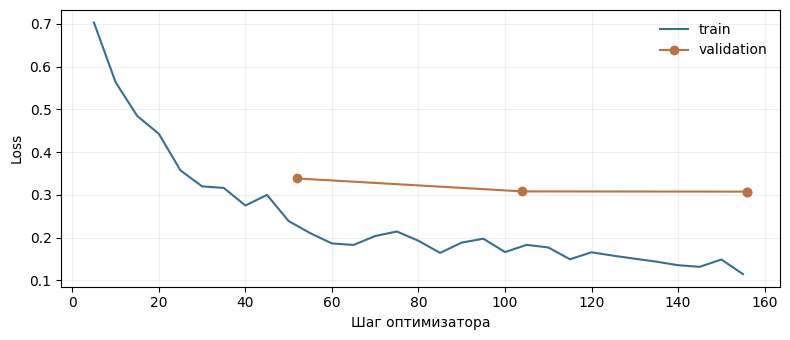

In [13]:
history = pd.DataFrame(trainer.state.log_history)
train_log = history.dropna(subset=["loss"])
eval_log = history.dropna(subset=["eval_loss"])
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(train_log["step"], train_log["loss"], label="train", color="#386f8f")
ax.plot(eval_log["step"], eval_log["eval_loss"], marker="o", label="validation", color="#bd7242")
ax.set(xlabel="Шаг оптимизатора", ylabel="Loss")
ax.grid(alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("outputs/loss.png", dpi=180)
plt.show()

### Как читать loss?

Train loss усредняется между логами, validation считается на отложенных диалогах. После второй эпохи validation почти не менялся; итог 0.307.

## 5. Тест

60 исходных случаев: 40 EN, 20 RU. Метрики шаблона: набор функций и точное совпадение аргументов; сломанный JSON считается ошибкой.

In [14]:
TOOL_CALL_PATTERN = re.compile(r"<tool_call>\s*(.*?)\s*</tool_call>", re.DOTALL)


def parse_tool_calls(text):

    blocks = TOOL_CALL_PATTERN.findall(text)
    if len(blocks) != text.count("<tool_call>"):
        return None
    try:
        calls = [json.loads(block) for block in blocks]
    except ValueError:
        return None
    if not all(isinstance(call, dict) and isinstance(call.get("name"), str) and isinstance(call.get("arguments"), dict) for call in calls):
        return None
    return [{"name": call["name"], "arguments": call["arguments"]} for call in calls]


ARGUMENT_DEFAULTS = {
    tool["function"]["name"]: {name: spec["default"] for name, spec in tool["function"]["parameters"]["properties"].items() if "default" in spec}
    for tool in SMART_HOME_TOOLS
}


def canonical(calls):

    filled = [{"name": c["name"], "arguments": {**ARGUMENT_DEFAULTS.get(c["name"], {}), **c["arguments"]}} for c in calls]
    return sorted(json.dumps(c, sort_keys=True) for c in filled)


def evaluate(model, tokenizer, cases):
    rows = []
    for case in cases:
        messages = case["messages"]
        if messages[0]["role"] != "system":
            messages = [{"role": "system", "content": SYSTEM_PROMPT}, *messages]
        output = generate(model, tokenizer, messages, SMART_HOME_TOOLS)
        calls = parse_tool_calls(output)
        tools_ok = calls is not None and {call["name"] for call in calls} == set(case["expected_tools"])
        rows.append({
            "id": case["id"], "lang": case["lang"], "output": output,
            "tools_ok": tools_ok,
            "args_ok": tools_ok and canonical(calls) == canonical(case["expected_calls"]),
        })
    return pd.DataFrame(rows)


def summarize(results):
    return results.groupby("lang").agg(tool_set_accuracy=("tools_ok", "mean"), exact_match=("args_ok", "mean"))

In [15]:
del trainer
gc.collect()
torch.cuda.empty_cache()
model.eval()
cases = read_jsonl("data/test_cases.jsonl")
base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, revision=MODEL_REVISION, dtype=torch.bfloat16).to("cuda")
base_results = evaluate(base_model, tokenizer, cases)
sft_results = evaluate(model, tokenizer, cases)
scores = pd.concat([
    summarize(base_results).assign(model="base"),
    summarize(sft_results).assign(model="sft"),
]).reset_index()[["model", "lang", "tool_set_accuracy", "exact_match"]]
base_results.to_json("outputs/base_predictions.json", orient="records", force_ascii=False, indent=2)
sft_results.to_json("outputs/sft_predictions.json", orient="records", force_ascii=False, indent=2)
del base_model
gc.collect()
torch.cuda.empty_cache()
scores.to_csv("outputs/eval_results.csv", index=False)
display(scores)

,model,lang,tool_set_accuracy,exact_match
0,base,en,0.75,0.550
1,base,ru,0.75,0.200
2,sft,en,0.95,0.925
3,sft,ru,0.85,0.850


Те же десять запросов после обучения.

In [16]:
comparison["after_sft"] = [answer(model, tokenizer, prompt) for prompt in BASELINE_PROMPTS]
display(comparison)
comparison.to_json("outputs/comparison.json", orient="records", force_ascii=False, indent=2)

,prompt,base,after_sft
0,Turn on the kitchen light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>","<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>"
1,Set the bedroom to 23 degrees.,"<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 23}}\n</tool_call>","<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 23}}\n</tool_call>"
2,What is the state of the living room?,"<tool_call>\n{""name"": ""get_room_state"", ""arguments"": {""room"": ""living_room""}}\n</tool_call>","<tool_call>\n{""name"": ""get_room_state"", ""arguments"": {""room"": ""living_room""}}\n</tool_call>"
3,Add two cartons of milk to my shopping list.,"<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""milk"", ""quantity"": 2}}\n</tool_call>","<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""milk""}}\n</tool_call>"
4,Set a 10-minute timer labeled pasta.,"<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""pasta""}}\n</tool_call>","<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""pasta""}}\n</tool_call>"
5,Turn off the bedroom light and set its temperature to 20 degrees.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 20}}\n</tool...","<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 20}}\n</tool..."
6,Turn off all lights.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""all"", ""state"": ""off""}}\n</tool_call>","<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_c..."
7,Hello!,How can I help you today?,Hello! How can I help you?
8,Open the garage.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""garage"", ""state"": ""on""}}\n</tool_call>","I can't control the garage. I can turn lights on or off in the kitchen, bedroom or living room, set temperatures there, add items to your shopping list or start timers."
9,Turn on the light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""living_room"", ""state"": ""on""}}\n</tool_call>",Which room should I turn it on in?


## 6. Агент

Каждый вызов выполняем в симуляторе, ответ добавляем как tool и продолжаем генерацию. Останавливаемся после текстового ответа или четырёх шагов.

In [17]:
def run_agent(model, tokenizer, home, messages, max_steps=4):
    for _ in range(max_steps):
        output = generate(model, tokenizer, messages, SMART_HOME_TOOLS)
        calls = parse_tool_calls(output)
        content = TOOL_CALL_PATTERN.sub("", output).strip() if calls else output
        reply = {"role": "assistant", "content": content}
        if calls:
            reply["tool_calls"] = [
                {"type": "function", "function": call} for call in calls
            ]
        messages.append(reply)
        if not calls:
            break
        for call in calls:
            result = home.call(call["name"], call["arguments"])
            messages.append({
                "role": "tool", "name": call["name"],
                "content": json.dumps(result, ensure_ascii=False),
            })

In [18]:
scenarios = [
    ["Turn on the kitchen light."],
    ["Turn on the kitchen light and set it to 23 degrees."],
    ["Make it two degrees warmer in the bedroom.", "Two more degrees."],
    ["Thanks!"],
    ["Open the garage."],
]
agent_results = []
for prompts in scenarios:
    home = SmartHome()
    messages = [{"role": "system", "content": SYSTEM_PROMPT}]
    for prompt in prompts:
        messages.append({"role": "user", "content": prompt})
        run_agent(model, tokenizer, home, messages)
    print("=" * 80)
    show_dialog(messages[1:])
    print(f"дом: {json.dumps(home.snapshot(), ensure_ascii=False)}")
    agent_results.append({"prompts": prompts, "messages": messages, "state": home.snapshot()})
Path("outputs/agent_scenarios.json").write_text(json.dumps(agent_results, ensure_ascii=False, indent=2))

[user] Turn on the kitchen light.
[assistant] 
    -> turn_light({"room": "kitchen", "state": "on"})
[tool] {"room": "kitchen", "light": "on", "temperature": 21}
[assistant] The kitchen light is on.
дом: {"rooms": {"kitchen": {"light": "on", "temperature": 21}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}


[user] Turn on the kitchen light and set it to 23 degrees.
[assistant] 
    -> turn_light({"room": "kitchen", "state": "on"})
    -> set_temperature({"room": "kitchen", "value": 23})
[tool] {"room": "kitchen", "light": "on", "temperature": 21}
[tool] {"room": "kitchen", "light": "on", "temperature": 23}
[assistant] The kitchen light is on and it's set to 23 degrees.
дом: {"rooms": {"kitchen": {"light": "on", "temperature": 23}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}


[user] Make it two degrees warmer in the bedroom.
[assistant] Which room should I warm up?
[user] Two more degrees.
[assistant] 
    -> set_temperature({"room": "bedroom", "value": 24})
[tool] {"room": "bedroom", "light": "off", "temperature": 24}
[assistant] The bedroom is now at 24 degrees.
дом: {"rooms": {"kitchen": {"light": "off", "temperature": 21}, "bedroom": {"light": "off", "temperature": 24}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}
[user] Thanks!
[assistant] You're welcome!
дом: {"rooms": {"kitchen": {"light": "off", "temperature": 21}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}


[user] Open the garage.
[assistant] I can't control the garage. I can turn lights on or off in the kitchen, bedroom or living room, set temperatures there, add items to your shopping list or start timers.
дом: {"rooms": {"kitchen": {"light": "off", "temperature": 21}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}


6607

Чат использует тот же агентный цикл и показывает текущее состояние дома.

In [19]:
launch_chat(model, tokenizer, SmartHome(), run_agent)

## Результаты

### Как изменилось качество?

Exact match вырос с 26/60 до 54/60; набор функций совпал в 55/60 случаев после SFT.

### Что видно по десяти запросам?

SFT заменил room=all тремя вызовами, отказался управлять гаражом и начал уточнять комнату; количество молока потерял.

### Что получилось у агента?

Все вызовы выполнены, результаты вернулись в историю. Относительный нагрев провален: модель не прочитала температуру и получила 24°C вместо 25°C.

### Где остались ошибки?

На тесте остались вызовы для неподдерживаемых запросов, ошибки количества и пропуски нужных действий.